# Proyecto Aplicado — Clasificación de stroke con LDA/QDA, KNN, árboles y ensambles

**Dataset:** Stroke Prediction Dataset (Kaggle, fedesoriano): https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset

**Objetivo:** clasificar el registro `stroke = 1` a partir de 10 variables clínicas y demográficas, comparando las cuatro familias de modelos sobre un solo train/test split. Es un ejercicio académico de clasificación de registros; no una validación para uso clínico.

**Equipo:** Ángel Esqueda Ochoa, Ivan Reyes Pedroza y Andoreni Claudio Flores Alcocer.

**Preparación del documento y metadatos:** Ivan Reyes Pedroza.

Esta copia conserva la exploración y los modelos del proyecto original, corrige la preparación durante la validación cruzada y añade una conclusión basada en los resultados que se calculan al ejecutar el notebook completo.


In [1]:
from pathlib import Path
import hashlib
import importlib.metadata as metadata
import os
import platform

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from IPython.display import display, Markdown

from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                     cross_val_score, cross_val_predict)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, precision_recall_curve,
                             average_precision_score)

sns.set_theme(style="whitegrid", context="notebook")
UP_BLUE, UP_RED, UP_GOLD = "#003366", "#BA0C2F", "#C69214"
SEED = 42
N_JOBS = min(4, os.cpu_count() or 1)

# El CSV puede estar en el directorio de ejecución o un nivel arriba del notebook.
rutas_datos = [Path("healthcare-dataset-stroke-data.csv"),
               Path("../healthcare-dataset-stroke-data.csv")]
DATA_PATH = next((ruta for ruta in rutas_datos if ruta.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Coloca healthcare-dataset-stroke-data.csv junto al notebook o un nivel arriba.")
print("Python:", platform.python_version())
for paquete in ["numpy", "pandas", "scikit-learn", "matplotlib", "seaborn", "statsmodels"]:
    print(f"{paquete}: {metadata.version(paquete)}")
print("Semilla:", SEED, "| procesos CV:", N_JOBS)
print("SHA256 dataset:", hashlib.sha256(DATA_PATH.read_bytes()).hexdigest())

# Cada fit, incluido el de cada fold, estima su propia mediana.
# Solo KNN necesita estandarizar para que la distancia no dependa de las unidades.
def preparar_modelo(estimador, escalar=False):
    pasos = [("imputacion", SimpleImputer(strategy="median"))]
    if escalar:
        pasos.append(("escala", StandardScaler()))
    pasos.append(("modelo", estimador))
    return Pipeline(pasos)

df = pd.read_csv(DATA_PATH)
assert df.shape == (5110, 12), "El archivo no corresponde al dataset revisado."
assert df["id"].is_unique
assert set(df["stroke"].unique()) == {0, 1}
print(df.shape)
df.head()


Python: 3.12.14
numpy: 2.3.5
pandas: 2.2.3
scikit-learn: 1.9.1
matplotlib: 3.11.2
seaborn: 0.13.2
statsmodels: 0.15.0
Semilla: 42 | procesos CV: 4
SHA256 dataset: 644d473b05d2797006bd94865e4f8bb057f0c721617911613c82c8fcfc707420
(5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


## Parte 1 - EDA

#### Revisamos lo que importa para clasificar con este dataset: tipos de variable, faltantes (los declarados y los escondidos), balance de clases y relación de cada predictor con stroke.

In [2]:
# tipos de variable y valores unicos por columna
resumen = pd.DataFrame({"tipo": df.dtypes.astype(str),
                        "valores_unicos": df.nunique(),
                        "faltantes": df.isna().sum(),
                        "% faltantes": (df.isna().mean() * 100).round(2)})
display(resumen)

numericas = ["age", "avg_glucose_level", "bmi"]
binarias = ["hypertension", "heart_disease"]
categoricas = ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]

for col in categoricas:
    print("\n", df[col].value_counts())

,tipo,valores_unicos,faltantes,% faltantes
id,int64,5110,0,0.00
gender,object,3,0,0.00
age,float64,104,0,0.00
hypertension,int64,2,0,0.00
heart_disease,int64,2,0,0.00
ever_married,object,2,0,0.00
work_type,object,5,0,0.00
Residence_type,object,2,0,0.00
avg_glucose_level,float64,3979,0,0.00
bmi,float64,418,201,3.93



 gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

 ever_married
Yes    3353
No     1757
Name: count, dtype: int64

 work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64

 Residence_type
Urban    2596
Rural    2514
Name: count, dtype: int64

 smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: int64


stroke
0    4861
1     249
Name: count, dtype: int64
Tasa base de stroke: 4.87%
Accuracy de un modelo que siempre predice 'no stroke': 95.13%


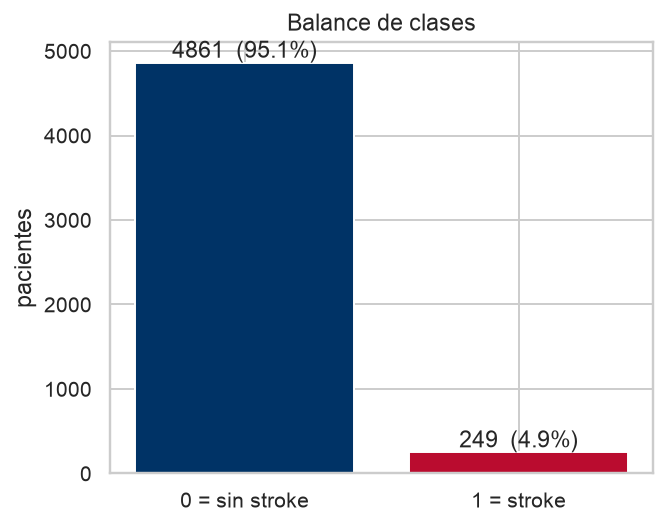

In [3]:
# balance de clases
conteo = df["stroke"].value_counts()
tasa_base = df["stroke"].mean()
print(conteo)
print(f"Tasa base de stroke: {tasa_base:.2%}")
print(f"Accuracy de un modelo que siempre predice 'no stroke': {1 - tasa_base:.2%}")

plt.figure(figsize=(5, 4))
plt.bar(["0 = sin stroke", "1 = stroke"], conteo.values, color=[UP_BLUE, UP_RED])
for i, v in enumerate(conteo.values):
    plt.text(i, v + 60, f"{v}  ({v / len(df):.1%})", ha="center")
plt.title("Balance de clases")
plt.ylabel("pacientes")
plt.show()

#### Solo ~5% de los pacientes tuvo un stroke. Un modelo que siempre diga "no stroke" tendría ~95% de accuracy sin haber aprendido nada, así que accuracy no puede ser nuestra métrica principal.

In [4]:
# faltantes "reales" (bmi) y faltantes "escondidos" (smoking_status == 'Unknown')
print("bmi faltante:", df["bmi"].isna().sum(), f"({df['bmi'].isna().mean():.1%})")
print("smoking_status == 'Unknown':", (df["smoking_status"] == "Unknown").sum(),
      f"({(df['smoking_status'] == 'Unknown').mean():.1%})")

# el faltante de bmi es al azar respecto al target?
tabla_bmi = (df.assign(bmi_faltante=df["bmi"].isna())
               .groupby("bmi_faltante")["stroke"].agg(n="size", strokes="sum", tasa="mean"))
print("\n", tabla_bmi)

# quienes son los 'Unknown' de tabaquismo?
print("\nEdad promedio por smoking_status:")
print(df.groupby("smoking_status")["age"].agg(["mean", "median"]).round(1))
print("\n% de menores de 18 dentro de 'Unknown':",
      f"{(df.loc[df['smoking_status'] == 'Unknown', 'age'] < 18).mean():.1%}")

bmi faltante: 201 (3.9%)
smoking_status == 'Unknown': 1544 (30.2%)

                  n  strokes      tasa
bmi_faltante                         
False         4909      209  0.042575
True           201       40  0.199005

Edad promedio por smoking_status:
                 mean  median
smoking_status               
Unknown          30.2    23.0
formerly smoked  54.9    57.0
never smoked     46.7    47.0
smokes           47.1    47.0

% de menores de 18 dentro de 'Unknown': 44.2%


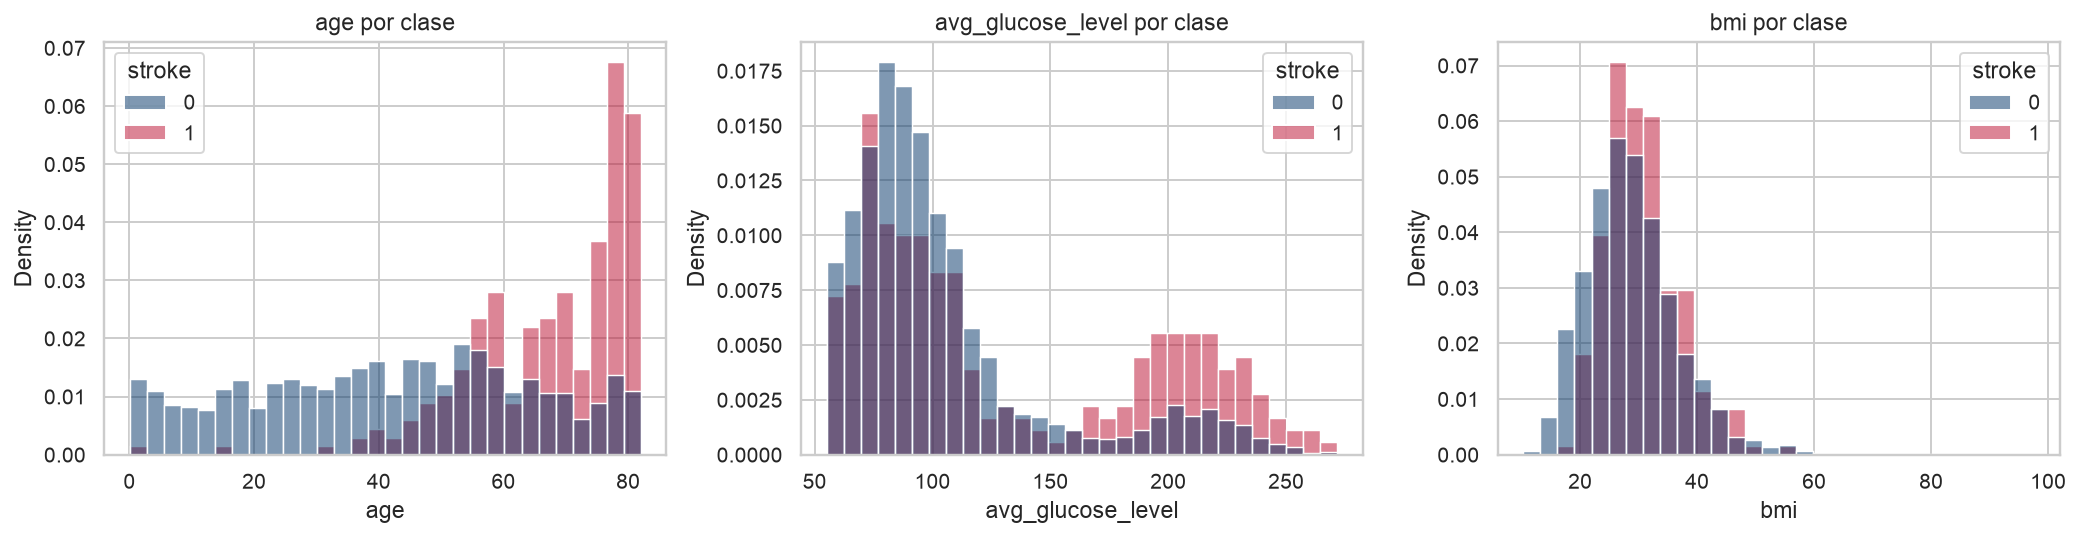

          age        avg_glucose_level           bmi      
         mean    std              mean    std   mean   std
stroke                                                    
0       41.97  22.29            104.80  43.85  28.82  7.91
1       67.73  12.73            132.54  61.92  30.47  6.33


In [5]:
# distribucion de las variables numericas dentro de cada clase
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, numericas):
    sns.histplot(data=df, x=col, hue="stroke", stat="density", common_norm=False,
                 bins=30, palette=[UP_BLUE, UP_RED], alpha=0.5, ax=ax)
    ax.set_title(f"{col} por clase")
plt.tight_layout()
plt.show()

print(df.groupby("stroke")[numericas].agg(["mean", "std"]).round(2))

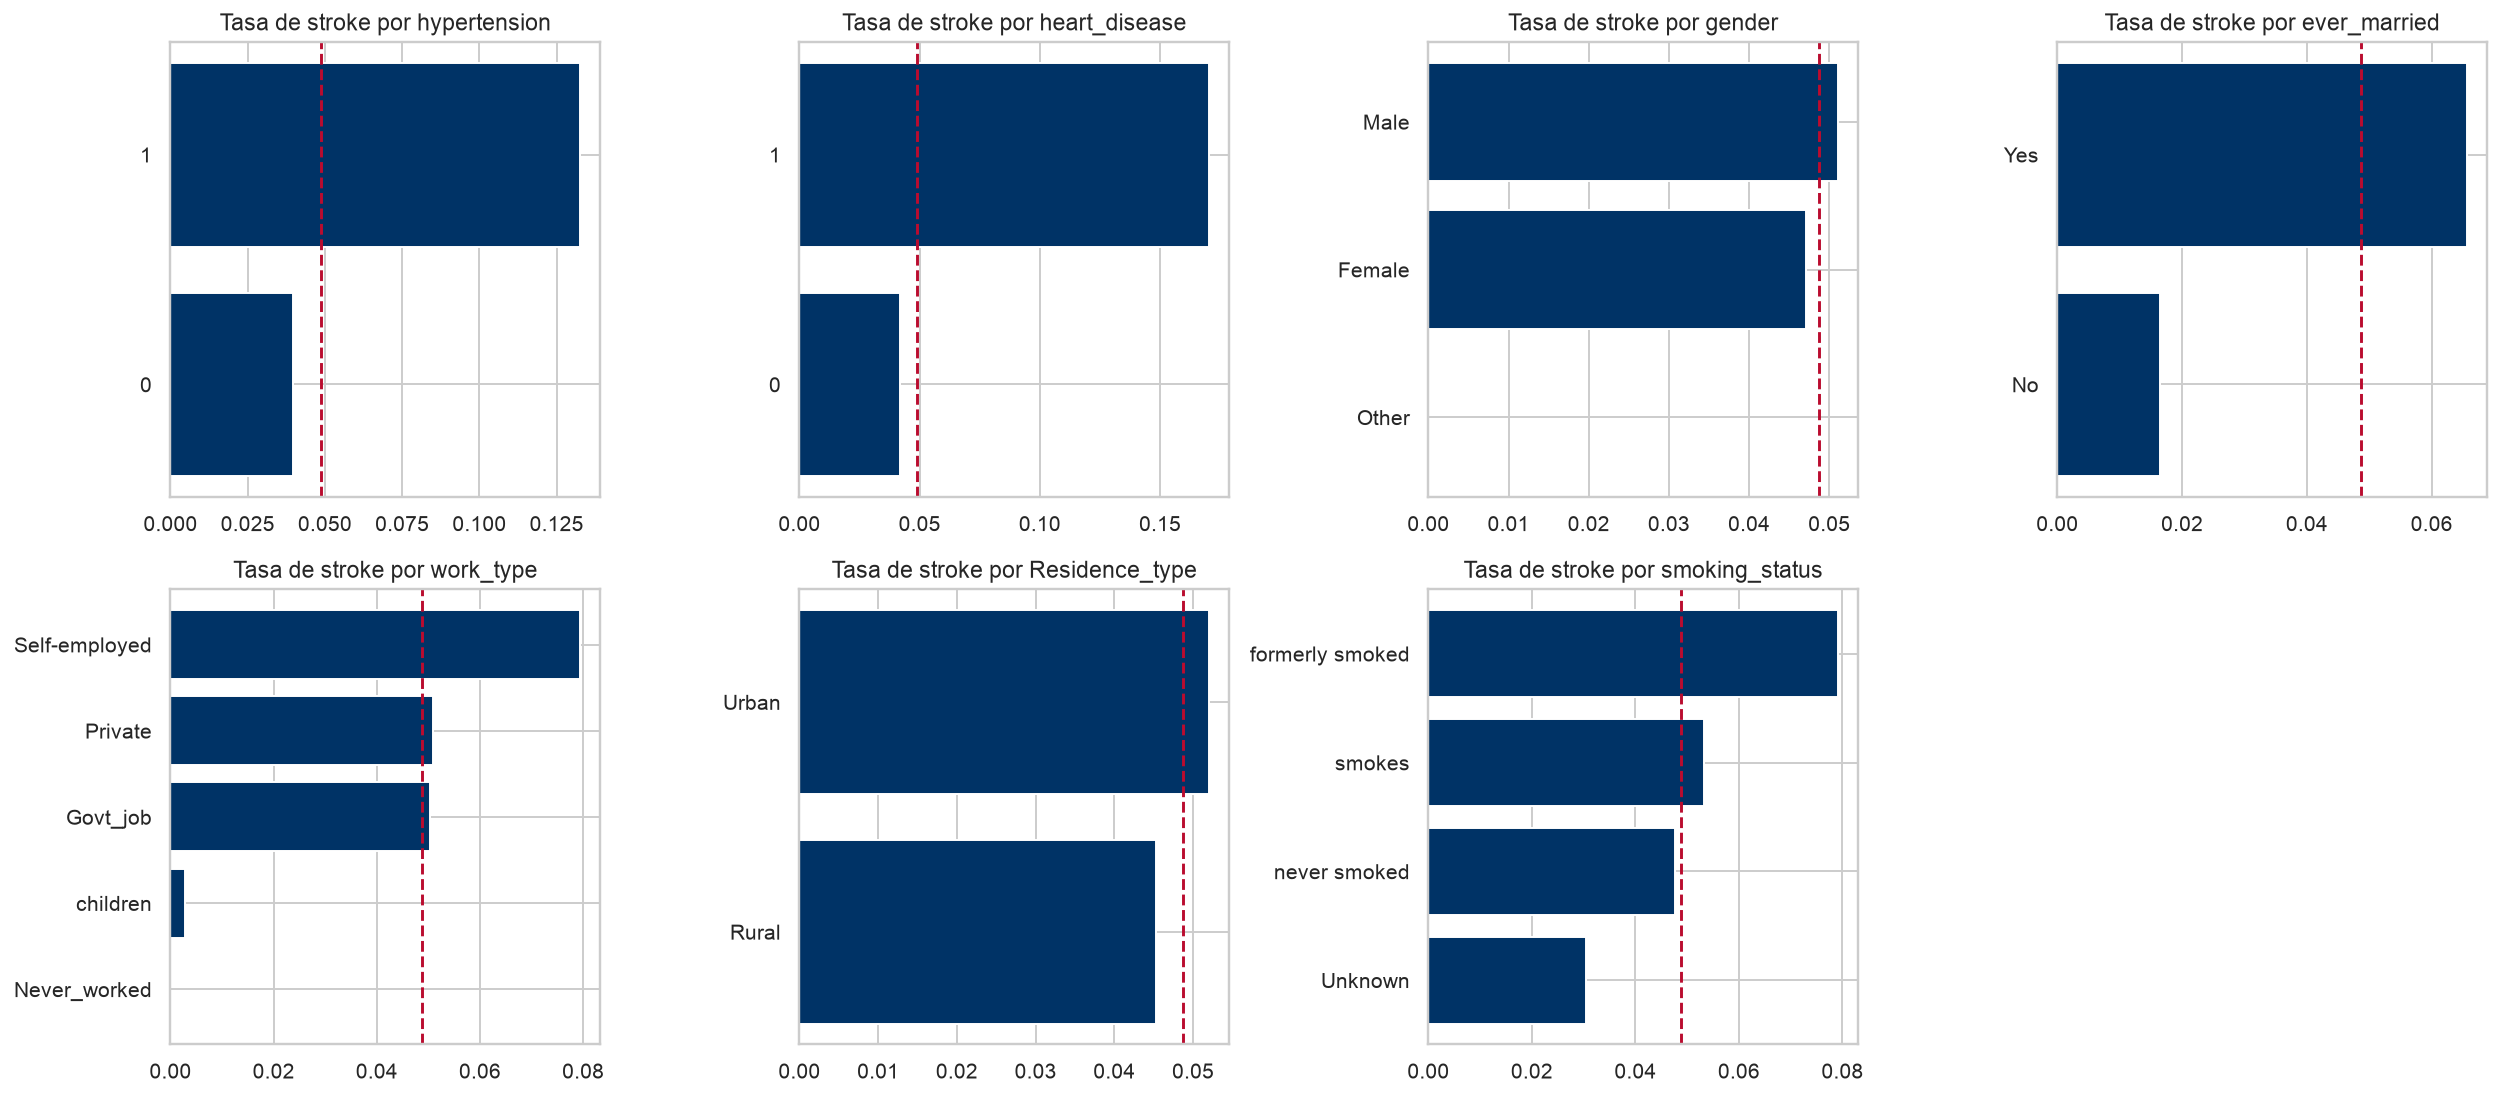

                  n  strokes
work_type                   
Govt_job        657       33
Never_worked     22        0
Private        2925      149
Self-employed   819       65
children        687        2
           n  strokes
gender               
Female  2994      141
Male    2115      108
Other      1        0


In [6]:
# tasa de stroke por categoria (la linea punteada es la tasa base)
cols_cat = binarias + categoricas
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.ravel()
for ax, col in zip(axes, cols_cat):
    tasas = df.groupby(col)["stroke"].mean().sort_values()
    ax.barh(tasas.index.astype(str), tasas.values, color=UP_BLUE)
    ax.axvline(tasa_base, color=UP_RED, ls="--", lw=1.5)
    ax.set_title(f"Tasa de stroke por {col}")
axes[-1].axis("off")
plt.tight_layout()
plt.show()

# categorias con muy pocos casos positivos
print(df.groupby("work_type")["stroke"].agg(n="size", strokes="sum"))
print(df.groupby("gender")["stroke"].agg(n="size", strokes="sum"))

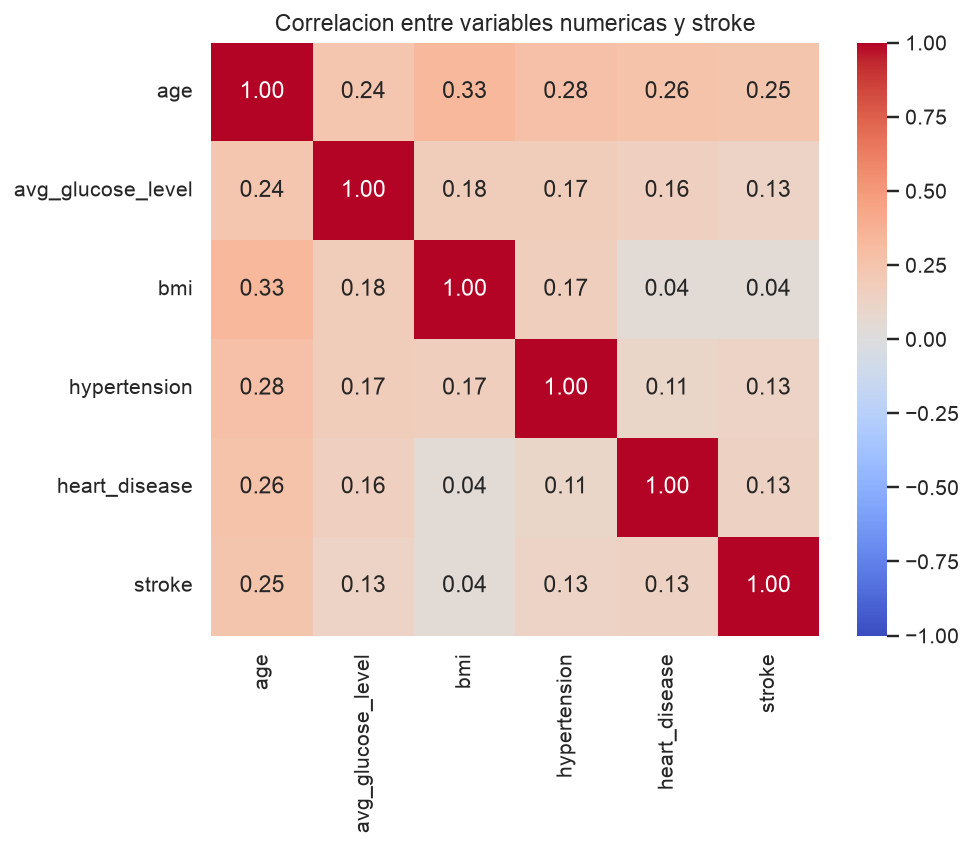

In [7]:
# correlacion entre variables numericas/binarias y el target
plt.figure(figsize=(7, 5.5))
sns.heatmap(df[numericas + binarias + ["stroke"]].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1)
plt.title("Correlacion entre variables numericas y stroke")
plt.show()

---

## Parte 2 — Limpieza, matriz de diseño y train/test split

Quitamos `id`, que identifica registros, y la única observación con `gender = Other`. Esta exclusión limita lo que puede decirse de esa categoría y no debe interpretarse como una regla general.

Hacemos primero un solo split 75/25 estratificado. Las categorías de las dummies se fijan con train y se aplican al test con el mismo orden de columnas. No se consulta el objetivo de test para elegir predictores, modelos, hiperparámetros ni umbrales.

`X_train` conserva los BMI faltantes. La imputación por mediana está dentro de cada Pipeline, por lo que se ajusta nuevamente solo con la parte de entrenamiento de cada fold. KNN agrega también un StandardScaler dentro del Pipeline. Usamos los mismos cinco folds estratificados para comparar las búsquedas. El EDA inicial describe el archivo completo; la evaluación final de modelos y umbrales queda reservada al test.


In [8]:
# Limpieza explícita del dataset, todavía sin imputar ni crear dummies.
datos = df.drop(columns="id").copy()
datos = datos.loc[datos["gender"] != "Other"].copy()
X_crudo = datos.drop(columns="stroke")
y = datos["stroke"].astype(int)
print("Predictores originales:", X_crudo.shape)
print(list(X_crudo.columns))


Predictores originales: (5109, 10)
['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status']


In [9]:
# Separamos primero registros crudos; ambos conjuntos conservan sus índices originales.
X_crudo_train, X_crudo_test, y_train, y_test = train_test_split(
    X_crudo, y, test_size=0.25, stratify=y, random_state=SEED)
assert set(X_crudo_train.index).isdisjoint(X_crudo_test.index)
assert len(X_crudo_train) + len(X_crudo_test) == len(datos)
assert X_crudo_train.index.equals(y_train.index)
assert X_crudo_test.index.equals(y_test.index)

# Vocabulario categórico aprendido únicamente de train.
# Este esquema fijo se comparte entre folds; no aprende estadísticas ni usa etiquetas.
categorias_train = {col: sorted(X_crudo_train[col].dropna().unique().tolist())
                    for col in categoricas}

def codificar_con_esquema_train(tabla):
    copia = tabla.copy()
    for col, categorias in categorias_train.items():
        desconocidas = set(copia[col].dropna().unique()) - set(categorias)
        if desconocidas:
            raise ValueError(f"Categorías no vistas en train para {col}: {desconocidas}")
        copia[col] = pd.Categorical(copia[col], categories=categorias)
    return pd.get_dummies(copia, columns=categoricas, drop_first=True).astype(float)

X_train = codificar_con_esquema_train(X_crudo_train)
X_test = codificar_con_esquema_train(X_crudo_test).reindex(columns=X_train.columns)
assert X_train.columns.equals(X_test.columns)
assert set(X_train.columns) == set(X_test.columns)
assert X_train.drop(columns="bmi").notna().all().all()
assert X_test.drop(columns="bmi").notna().all().all()

print("Matriz de diseño train:", X_train.shape)
print(list(X_train.columns))
print(f"BMI faltantes sin imputar: train={X_train['bmi'].isna().sum()}, test={X_test['bmi'].isna().sum()}")
print(f"Train: {X_train.shape}, positivos = {y_train.sum()} ({y_train.mean():.2%})")
print(f"Test:  {X_test.shape}, positivos = {y_test.sum()} ({y_test.mean():.2%})")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


Matriz de diseño train: (3831, 15)
['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'gender_Male', 'ever_married_Yes', 'work_type_Never_worked', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'Residence_type_Urban', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes']
BMI faltantes sin imputar: train=150, test=51
Train: (3831, 15), positivos = 187 (4.88%)
Test:  (1278, 15), positivos = 62 (4.85%)


---

## Parte 3 — LDA vs QDA

LDA supone normalidad multivariada dentro de cada clase y una matriz de covarianza compartida; QDA permite una matriz distinta por clase y una frontera curva (Clase 17). Revisamos gráficas, dispersión y restricciones de las dummies y comparamos candidatos mediante CV.

Con el mismo conjunto de variables, LDA estima menos matrices de covarianza que QDA y ofrece una frontera lineal más fácil de revisar. Conservamos LDA con todos los predictores como representante discriminante por esa preferencia de estabilidad e interpretación, definida sin consultar test. Es una elección razonada, no la afirmación de que siempre obtiene la máxima AUC CV: la tabla muestra también QDA con tres continuas, que puede dar una media algo mayor. Las desviaciones entre folds son descriptivas y no prueban equivalencia ni superioridad.


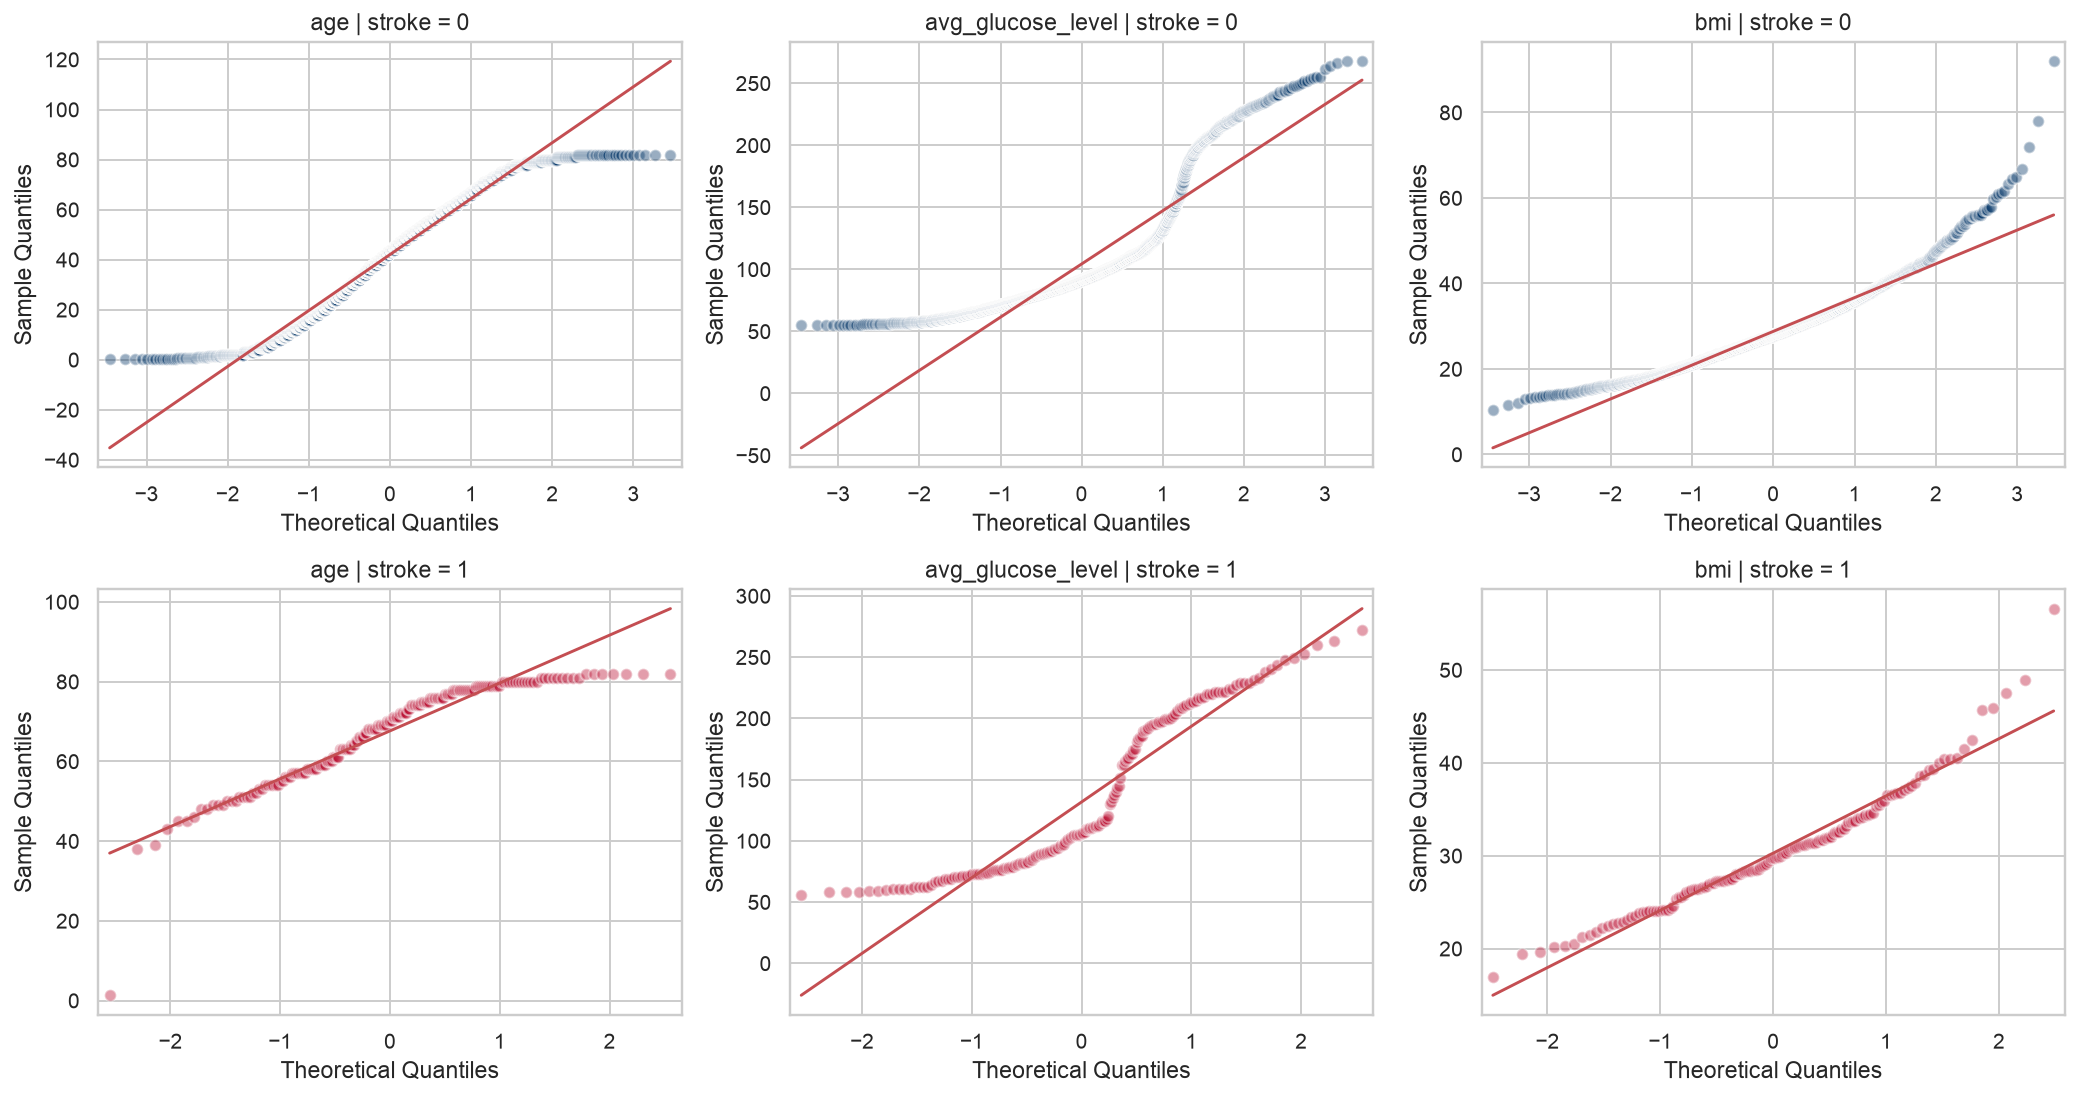

In [10]:
# QQ-plots de train, sin rellenar faltantes para la gráfica diagnóstica.
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for fila, clase in enumerate([0, 1]):
    for col_i, col in enumerate(numericas):
        valores = X_train.loc[y_train == clase, col].dropna()
        sm.qqplot(valores, line="s", ax=axes[fila, col_i],
                  markerfacecolor=UP_BLUE if clase == 0 else UP_RED,
                  markeredgecolor="white", alpha=0.4)
        axes[fila, col_i].set_title(f"{col} | stroke = {clase}")
plt.tight_layout()
plt.show()


In [11]:
# Diagnósticos sobre datos observados; no se usan para imputar los modelos.
print("Desviación estándar por clase (BMI usa valores observados):")
print(X_train.groupby(y_train)[numericas].std().round(2))
for clase in [0, 1]:
    print(f"\nMatriz de covarianza de continuas, stroke = {clase} (casos completos):")
    print(X_train.loc[y_train == clase, numericas].dropna().cov().round(1))

p = X_train.shape[1]
n_pos = int(y_train.sum())
positivos_completos = X_train.loc[y_train == 1].dropna()
sigma_1 = np.cov(positivos_completos.values, rowvar=False)
print(f"\nPredictores p = {p}, parámetros por matriz de covarianza = {p * (p + 1) // 2}")
print(f"Positivos en train = {n_pos}; completos para este diagnóstico = {len(positivos_completos)}")
print(f"Rango de la covarianza de clase 1, casos completos: {np.linalg.matrix_rank(sigma_1)} de {p}")
print("\nDummies con varianza cero dentro de clase 1:")
print(X_train.loc[y_train == 1].std().loc[lambda serie: serie == 0])


Desviación estándar por clase (BMI usa valores observados):
          age  avg_glucose_level   bmi
stroke                                
0       22.36              42.91  7.91
1       12.04              61.97  6.18

Matriz de covarianza de continuas, stroke = 0 (casos completos):
                     age  avg_glucose_level   bmi
age                499.0              197.9  61.6
avg_glucose_level  197.9             1783.6  52.7
bmi                 61.6               52.7  62.5

Matriz de covarianza de continuas, stroke = 1 (casos completos):
                     age  avg_glucose_level    bmi
age                131.8               36.3  -23.4
avg_glucose_level   36.3             3926.0  134.7
bmi                -23.4              134.7   38.2

Predictores p = 15, parámetros por matriz de covarianza = 120
Positivos en train = 187; completos para este diagnóstico = 153
Rango de la covarianza de clase 1, casos completos: 13 de 15

Dummies con varianza cero dentro de clase 1:
work_type_Neve

In [12]:
# LDA y QDA usan imputación dentro de cada fold, también al comparar subconjuntos.
clinicas = numericas + binarias
candidatos = {
    "LDA (todos los predictores)": (preparar_modelo(LinearDiscriminantAnalysis()), list(X_train.columns)),
    "LDA (5 clinicas)": (preparar_modelo(LinearDiscriminantAnalysis()), clinicas),
    "QDA (5 clinicas)": (preparar_modelo(QuadraticDiscriminantAnalysis()), clinicas),
    "LDA (3 continuas)": (preparar_modelo(LinearDiscriminantAnalysis()), numericas),
    "QDA (3 continuas)": (preparar_modelo(QuadraticDiscriminantAnalysis()), numericas),
}
filas = []
for nombre, (modelo, cols) in candidatos.items():
    scores = cross_val_score(modelo, X_train[cols], y_train, cv=cv, scoring="roc_auc", n_jobs=N_JOBS)
    filas.append({"modelo": nombre, "AUC CV promedio": scores.mean(),
                  "desv. est. entre folds": scores.std()})
tabla_da = pd.DataFrame(filas).set_index("modelo")
display(tabla_da.round(4))
print("Mayor AUC CV de los candidatos:", tabla_da["AUC CV promedio"].idxmax())
print("Conservamos LDA completo por el criterio explícito explicado arriba, antes de evaluar test.")


,AUC CV promedio,desv. est. entre folds
modelo,,
LDA (todos los predictores),0.8320,0.0356
LDA (5 clinicas),0.8333,0.0373
QDA (5 clinicas),0.8296,0.0333
LDA (3 continuas),0.8348,0.0415
QDA (3 continuas),0.8385,0.0325


Mayor AUC CV de los candidatos: QDA (3 continuas)
Conservamos LDA completo por el criterio explícito explicado arriba, antes de evaluar test.


In [13]:
lda = preparar_modelo(LinearDiscriminantAnalysis())
lda.fit(X_train, y_train)
auc_cv_lda = tabla_da.loc["LDA (todos los predictores)", "AUC CV promedio"]
lda_estimador = lda.named_steps["modelo"]
print("Mediana BMI aprendida por LDA en train:",
      lda.named_steps["imputacion"].statistics_[X_train.columns.get_loc("bmi")])
print("Priors estimados (pi_k):", lda_estimador.priors_.round(4))
print("\nCoeficientes discriminantes (escala original; no implican causalidad):")
print(pd.Series(lda_estimador.coef_[0], index=X_train.columns).sort_values().round(3))


Mediana BMI aprendida por LDA en train: 28.0
Priors estimados (pi_k): [0.9512 0.0488]

Coeficientes discriminantes (escala original; no implican causalidad):
ever_married_Yes                 -0.760
smoking_status_never smoked      -0.176
work_type_Self-employed          -0.128
gender_Male                      -0.065
bmi                              -0.022
smoking_status_formerly smoked   -0.018
avg_glucose_level                 0.008
smoking_status_smokes             0.048
age                               0.071
Residence_type_Urban              0.071
work_type_Private                 0.206
work_type_Never_worked            0.693
hypertension                      0.905
heart_disease                     0.953
work_type_children                1.258
dtype: float64


--- 

## Parte 4 - KNN

#### KNN clasifica por distancia euclidiana, así que primero estandarizamos (si no, la glucosa, que va aproximadamente de 55 a 272, pesaría mucho más que una dummy 0/1). Probamos dos conjuntos de predictores, los 15 y solo las 5 variables clínicas, porque la Clase 17 advierte que KNN sufre con muchos predictores.

In [14]:
Ks = [1, 5, 11, 21, 31, 51, 75, 101, 151, 201, 301, 401, 501, 701, 1001]

def buscar_knn(columnas):
    pipe = preparar_modelo(KNeighborsClassifier(), escalar=True)
    busqueda = GridSearchCV(pipe, {"modelo__n_neighbors": Ks}, cv=cv,
                            scoring="roc_auc", n_jobs=N_JOBS)
    busqueda.fit(X_train[columnas], y_train)
    return busqueda

knn_todas = buscar_knn(list(X_train.columns))
knn_clinicas = buscar_knn(clinicas)
for nombre, busqueda in [("15 predictores", knn_todas), ("5 clinicas", knn_clinicas)]:
    print(f"KNN ({nombre}): mejor K = {busqueda.best_params_['modelo__n_neighbors']}, AUC CV = {busqueda.best_score_:.4f}")


KNN (15 predictores): mejor K = 1001, AUC CV = 0.8058
KNN (5 clinicas): mejor K = 501, AUC CV = 0.8382


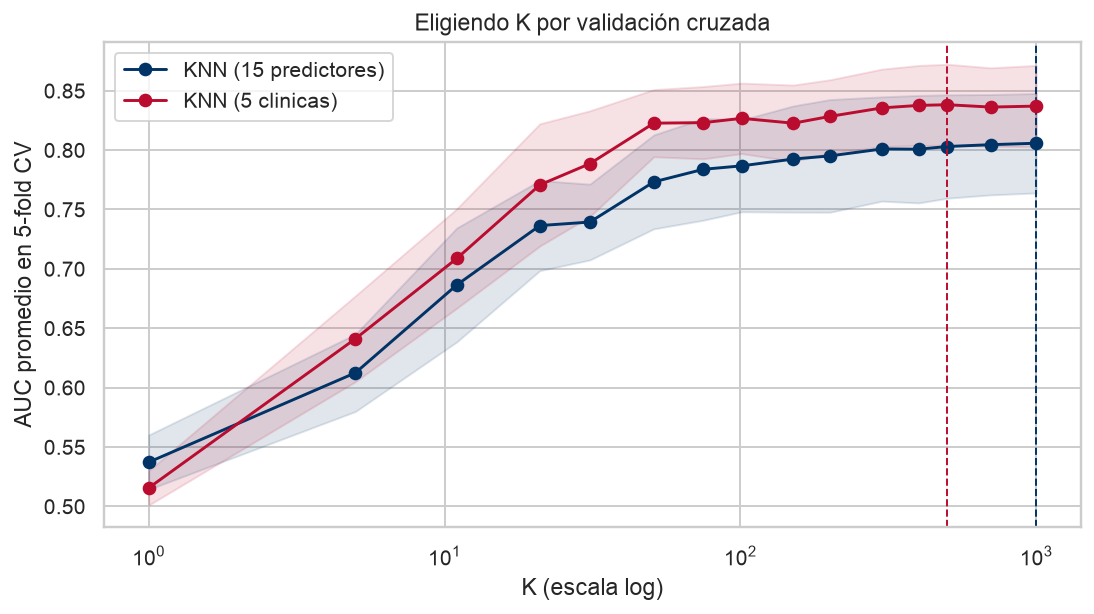

KNN final: {'modelo__n_neighbors': 501} con 5 predictores


In [15]:
plt.figure(figsize=(9, 4.5))
for nombre, busqueda, color in [("15 predictores", knn_todas, UP_BLUE),
                               ("5 clinicas", knn_clinicas, UP_RED)]:
    media = busqueda.cv_results_["mean_test_score"]
    desv = busqueda.cv_results_["std_test_score"]
    plt.plot(Ks, media, marker="o", color=color, label=f"KNN ({nombre})")
    plt.fill_between(Ks, media - desv, media + desv, color=color, alpha=0.12)
    plt.axvline(busqueda.best_params_["modelo__n_neighbors"], color=color, ls="--", lw=1)
plt.xscale("log")
plt.xlabel("K (escala log)")
plt.ylabel("AUC promedio en 5-fold CV")
plt.title("Eligiendo K por validación cruzada")
plt.legend()
plt.show()

if knn_clinicas.best_score_ > knn_todas.best_score_:
    knn, cols_knn = knn_clinicas, clinicas
else:
    knn, cols_knn = knn_todas, list(X_train.columns)
print("KNN final:", knn.best_params_, "con", len(cols_knn), "predictores")
if knn.best_params_["modelo__n_neighbors"] in [min(Ks), max(Ks)]:
    print("La mejor K está en el límite de la rejilla; con más tiempo conviene ampliar la búsqueda.")


---

## Parte 5 — Árbol de decisión

El árbol divide el espacio de predictores mediante cortes que reducen la impureza Gini (Clase 19). Un árbol profundo puede memorizar los casos de train. Probamos mínimos de observaciones por hoja y una penalización de complejidad `alpha`, que favorece árboles con menos hojas.

Los candidatos de alpha se fijan antes de la CV en una rejilla logarítmica; no se extraen de una ruta de poda ajustada con las etiquetas de los folds de validación. El alpha y el mínimo por hoja finales se eligen por AUC CV. La mediana de BMI se aprende de nuevo dentro de cada fold.


In [16]:
# Rejilla fijada previamente: no consulta etiquetas para construir candidatos.
alphas_arbol = np.r_[0.0, np.logspace(-6, -2, 17)]
rejilla_arbol = {"modelo__min_samples_leaf": [1, 20, 50, 100, 200, 400],
                 "modelo__ccp_alpha": alphas_arbol.tolist()}
arbol = GridSearchCV(preparar_modelo(DecisionTreeClassifier(criterion="gini", random_state=SEED)),
                     rejilla_arbol, cv=cv, scoring="roc_auc", n_jobs=N_JOBS)
arbol.fit(X_train, y_train)
mejor_arbol = arbol.best_estimator_
arbol_estimador = mejor_arbol.named_steps["modelo"]
print("Mejores hiperparámetros:", arbol.best_params_)
print(f"AUC CV = {arbol.best_score_:.4f}")
print(f"Hojas = {arbol_estimador.get_n_leaves()}, profundidad = {arbol_estimador.get_depth()}")

sin_podar = preparar_modelo(DecisionTreeClassifier(random_state=SEED)).fit(X_train, y_train)
sin_podar_estimador = sin_podar.named_steps["modelo"]
print(f"\nÁrbol sin podar: {sin_podar_estimador.get_n_leaves()} hojas, profundidad {sin_podar_estimador.get_depth()}")
print(f"AUC CV del árbol sin podar: {cross_val_score(sin_podar, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=N_JOBS).mean():.4f}")


Mejores hiperparámetros: {'modelo__ccp_alpha': 5.623413251903491e-06, 'modelo__min_samples_leaf': 200}
AUC CV = 0.8297
Hojas = 10, profundidad = 5

Árbol sin podar: 274 hojas, profundidad 18
AUC CV del árbol sin podar: 0.5439


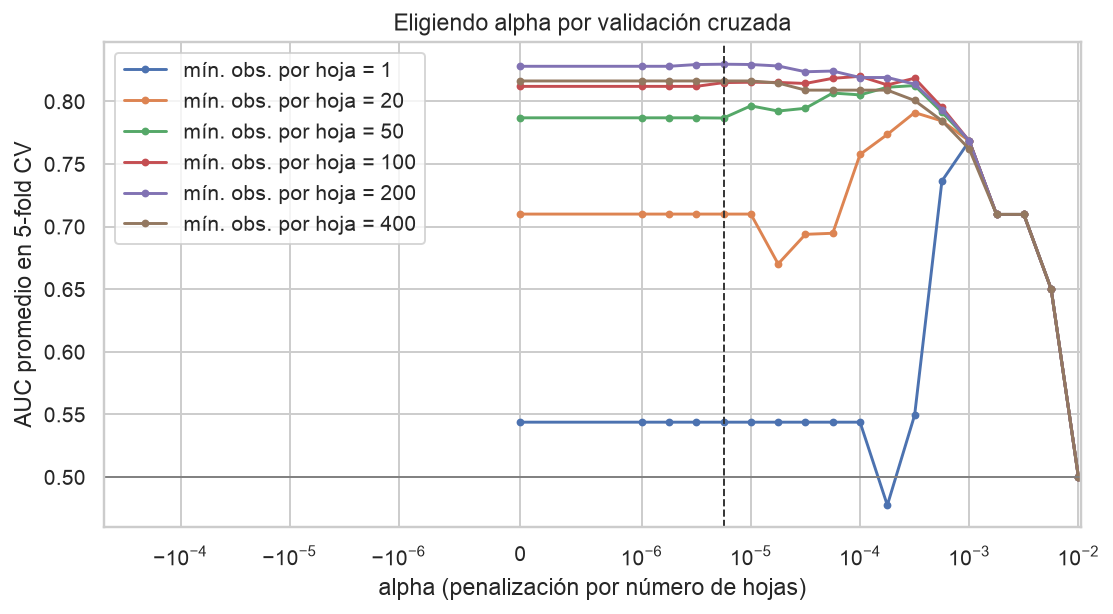

In [17]:
res_arbol = pd.DataFrame(arbol.cv_results_)
plt.figure(figsize=(9, 4.5))
for minimo, grupo in res_arbol.groupby("param_modelo__min_samples_leaf"):
    grupo = grupo.sort_values("param_modelo__ccp_alpha")
    plt.plot(grupo["param_modelo__ccp_alpha"].astype(float), grupo["mean_test_score"],
             marker=".", label=f"mín. obs. por hoja = {minimo}")
plt.axvline(arbol.best_params_["modelo__ccp_alpha"], color="#333333", ls="--", lw=1)
plt.axhline(0.5, color="gray", lw=1)
plt.xscale("symlog", linthresh=1e-6)
plt.xlabel("alpha (penalización por número de hojas)")
plt.ylabel("AUC promedio en 5-fold CV")
plt.title("Eligiendo alpha por validación cruzada")
plt.legend()
plt.show()


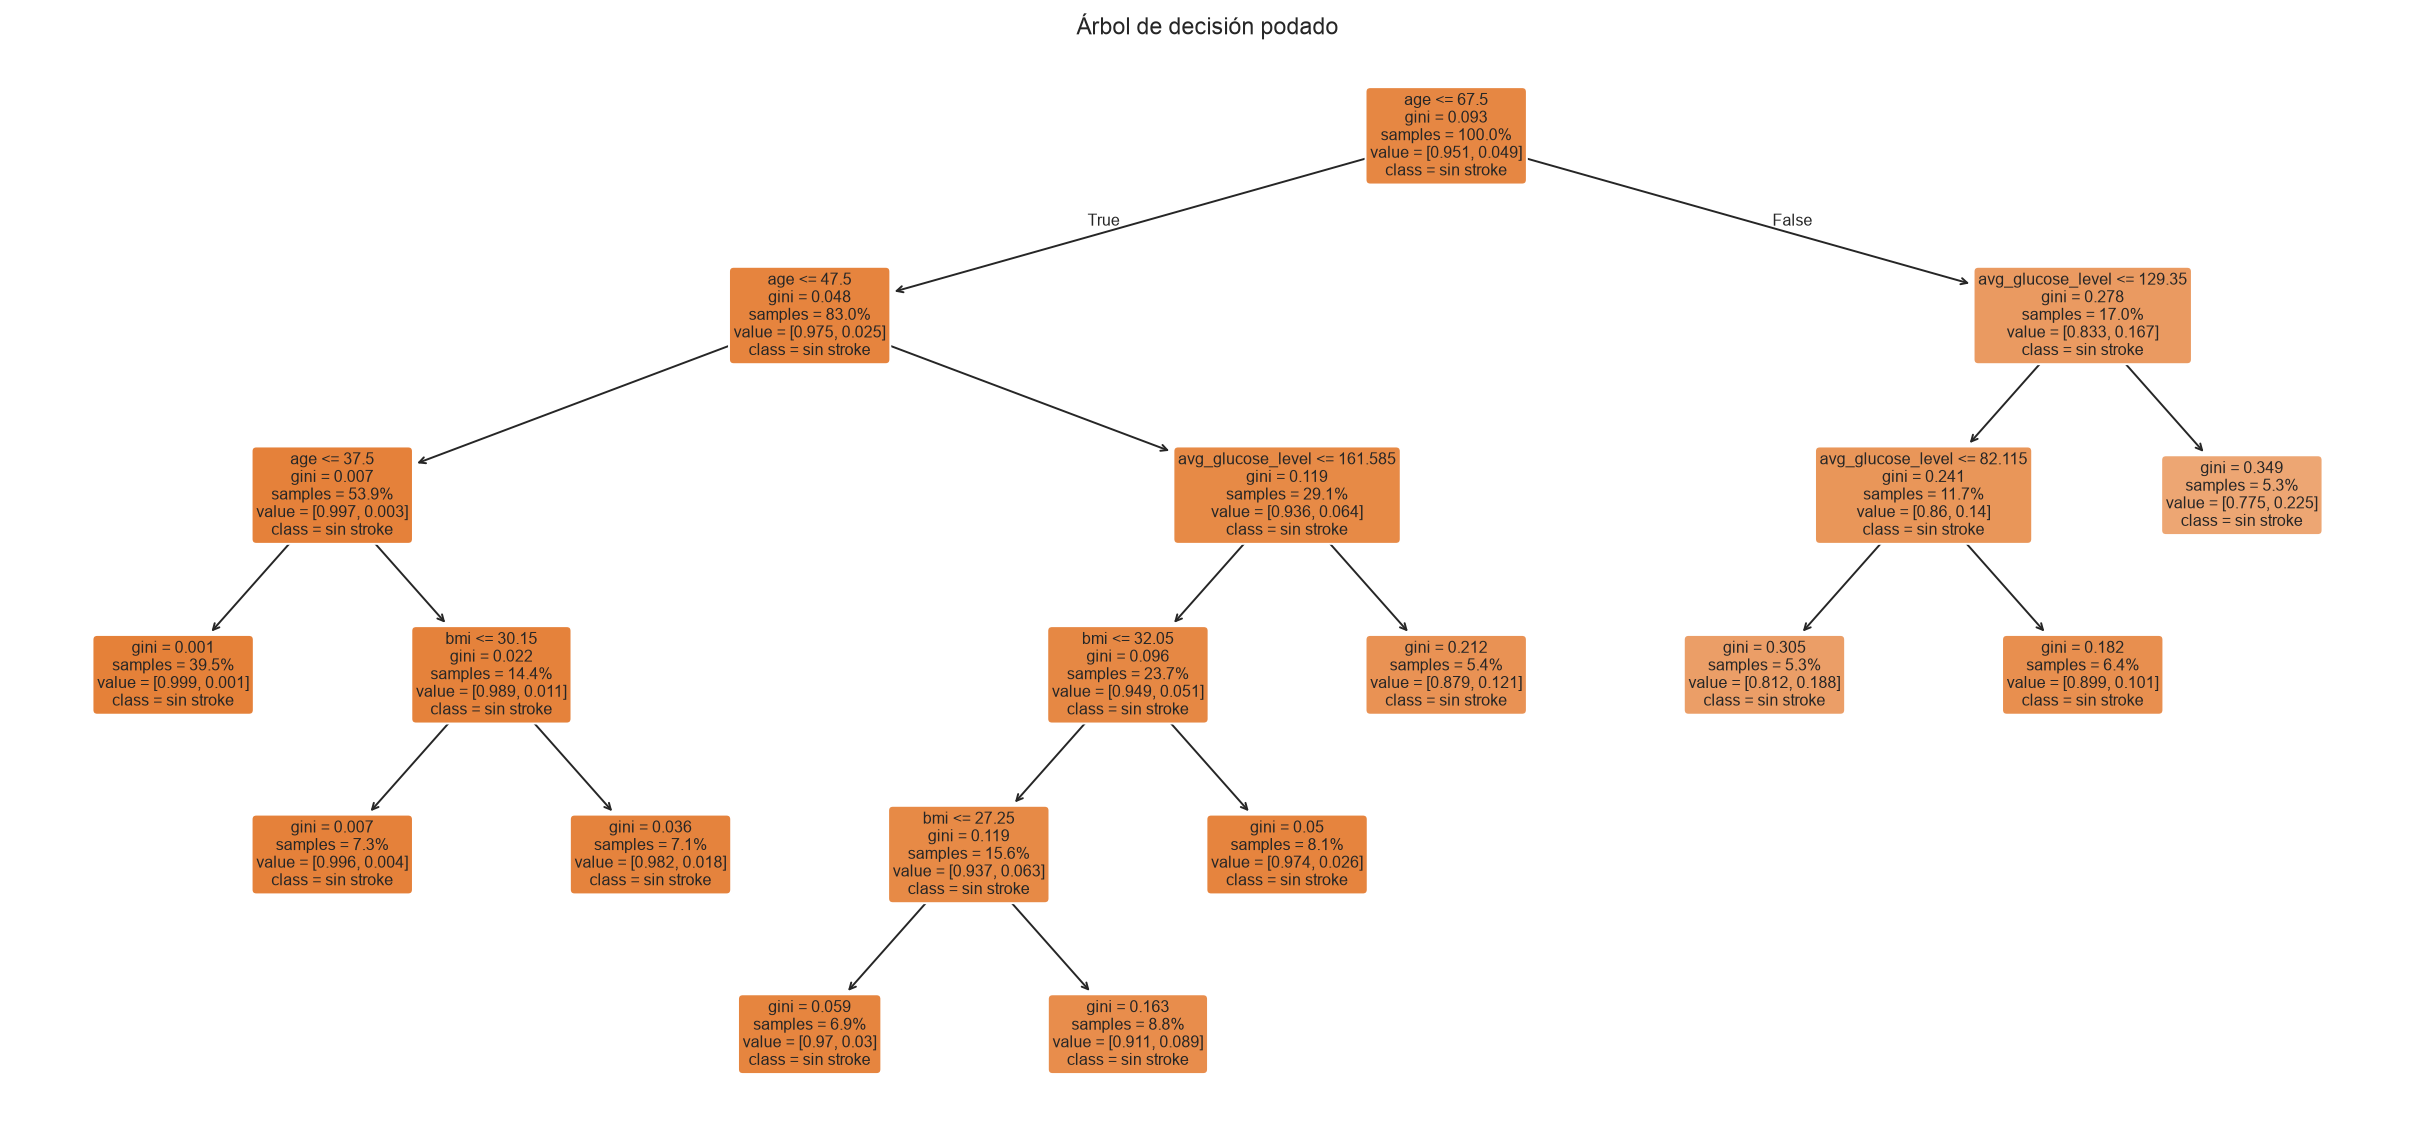

In [18]:
# Mostramos el estimador del Pipeline ya ajustado; las columnas conservan su orden.
plt.figure(figsize=(22, 10))
plot_tree(arbol_estimador, feature_names=list(X_train.columns),
          class_names=["sin stroke", "stroke"], filled=True, rounded=True,
          impurity=True, proportion=True, fontsize=8)
plt.title("Árbol de decisión podado")
plt.show()


---

## Parte 6 — Random Forest

### Random Forest promedia árboles entrenados en muestras bootstrap y, en cada corte, solo deja considerar m variables al azar para decorrelacionarlos (Clase 21). Elegimos m y el mínimo de observaciones por hoja por CV. Incluimos m = todas las variables, que es exactamente Bagging, para medir cuánto aporta la decorrelación.

In [19]:
rejilla_rf = {"modelo__max_features": [2, "sqrt", 6, None],
              "modelo__min_samples_leaf": [1, 5, 20, 50, 100]}
rf = GridSearchCV(preparar_modelo(RandomForestClassifier(n_estimators=300, random_state=SEED)),
                  rejilla_rf, cv=cv, scoring="roc_auc", n_jobs=N_JOBS)
rf.fit(X_train, y_train)
print("Mejores hiperparámetros:", rf.best_params_)
print(f"AUC CV = {rf.best_score_:.4f}")
res_rf = pd.DataFrame(rf.cv_results_)
res_rf["m"] = ["todas (Bagging)" if parametros["modelo__max_features"] is None
               else str(parametros["modelo__max_features"]) for parametros in res_rf["params"]]
display(res_rf.pivot(index="param_modelo__min_samples_leaf", columns="m",
                    values="mean_test_score").round(4))


Mejores hiperparámetros: {'modelo__max_features': 6, 'modelo__min_samples_leaf': 50}
AUC CV = 0.8443


m,2,6,sqrt,todas (Bagging)
param_modelo__min_samples_leaf,,,,
1,0.7993,0.8104,0.8041,0.8128
5,0.8272,0.8297,0.8340,0.8275
20,0.8378,0.8433,0.8421,0.8388
50,0.8385,0.8443,0.8415,0.8408
100,0.8368,0.8419,0.8385,0.8403


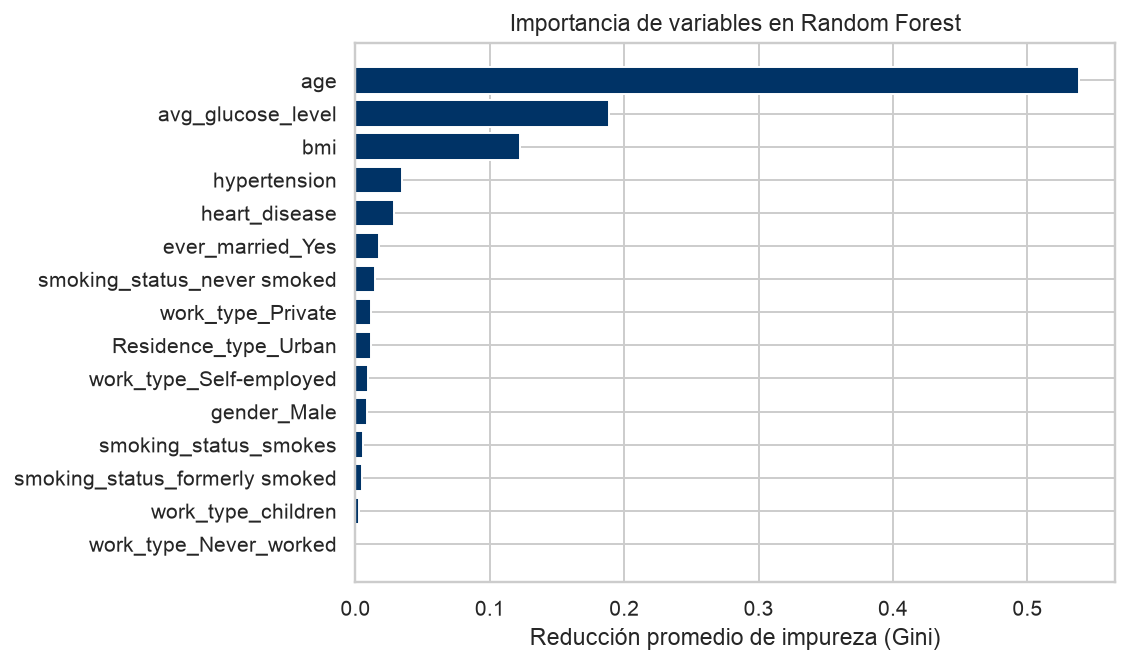

In [20]:
# Importancia basada en reducción de impureza; es descriptiva, no causal.
importancias = pd.Series(rf.best_estimator_.named_steps["modelo"].feature_importances_,
                         index=X_train.columns).sort_values()
plt.figure(figsize=(7, 5))
plt.barh(importancias.index, importancias.values, color=UP_BLUE)
plt.title("Importancia de variables en Random Forest")
plt.xlabel("Reducción promedio de impureza (Gini)")
plt.show()


Extra — Gradient Boosting

A diferencia de Random Forest, Boosting entrena árboles chicos en secuencia, cada uno sobre los errores del anterior. Elegimos por CV los tres hiperparámetros de la Clase 21: número de árboles B, shrinkage λ y profundidad d.

In [21]:
rejilla_gb = {"modelo__n_estimators": [100, 300, 500],
              "modelo__learning_rate": [0.01, 0.05, 0.1],
              "modelo__max_depth": [1, 2, 3]}
gb = GridSearchCV(preparar_modelo(GradientBoostingClassifier(random_state=SEED)),
                  rejilla_gb, cv=cv, scoring="roc_auc", n_jobs=N_JOBS)
gb.fit(X_train, y_train)
print("Mejores hiperparámetros:", gb.best_params_)
print(f"AUC CV = {gb.best_score_:.4f}")


Mejores hiperparámetros: {'modelo__learning_rate': 0.05, 'modelo__max_depth': 2, 'modelo__n_estimators': 100}
AUC CV = 0.8422


---

## Parte 7 — Comparación de modelos en test

Con aproximadamente 5% de positivos, accuracy por sí sola puede ocultar que no se detecta ninguno. Usamos ROC AUC como métrica principal para comparar la ordenación de los registros sin fijar un umbral. Precision, recall y F1 de la clase positiva describen el desempeño del punto de operación (Clase 12). Añadimos average precision (AP) y la curva Precision–Recall por el desbalance.

Seleccionamos el candidato de mayor AUC CV antes de consultar su AUC test. Las medias CV empleadas para ajustar hiperparámetros son puntuaciones de selección, no una estimación independiente después de seleccionar. El test permite describir cómo generalizan los modelos fijados; el ganador observado allí no se usa para volver a ajustar ni demuestra superioridad cierta.

Para el análisis académico tratamos los falsos negativos como especialmente relevantes. No hemos medido costes clínicos: maximizar F1 es un criterio de evaluación del ejercicio, no una recomendación médica.


In [22]:
modelos = {
    "LDA": (lda, list(X_train.columns)),
    "KNN": (knn.best_estimator_, cols_knn),
    "Arbol podado": (mejor_arbol, list(X_train.columns)),
    "Random Forest": (rf.best_estimator_, list(X_train.columns)),
    "Gradient Boosting": (gb.best_estimator_, list(X_train.columns)),
}
auc_cv = {"LDA": auc_cv_lda, "KNN": knn.best_score_, "Arbol podado": arbol.best_score_,
          "Random Forest": rf.best_score_, "Gradient Boosting": gb.best_score_}
modelo_seleccionado_cv = max(auc_cv, key=auc_cv.get)
print("Selección previa a test por AUC CV:", modelo_seleccionado_cv)

# OOF con hiperparámetros ya escogidos en train. No es CV anidada.
# Todas las medianas y, en KNN, escalas se vuelven a aprender dentro de cada fold.
# Elegimos umbrales con estas probabilidades de train; nunca con el test.
proba_oof = {}
for nombre, (modelo, cols) in modelos.items():
    proba_oof[nombre] = cross_val_predict(modelo, X_train[cols], y_train, cv=cv,
                                          method="predict_proba", n_jobs=N_JOBS)[:, 1]
    assert np.isfinite(proba_oof[nombre]).all()

# Las probabilidades de test se reservan para la evaluación de estos modelos fijados.
proba_test = {nombre: modelo.predict_proba(X_test[cols])[:, 1]
              for nombre, (modelo, cols) in modelos.items()}
assert all(np.isfinite(probabilidades).all() for probabilidades in proba_test.values())


Selección previa a test por AUC CV: Random Forest


Con el umbral de 0.5

Esta tabla muestra la trampa del accuracy: casi todos los modelos sacan ~95% sin detectar un solo stroke.

In [23]:
def metricas(y_real, proba, umbral):
    pred = (proba >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_real, pred, labels=[0, 1]).ravel()
    assert tn + fp + fn + tp == len(y_real)
    return {"umbral": umbral, "TP": tp, "FN": fn, "FP": fp, "TN": tn,
            "accuracy": accuracy_score(y_real, pred),
            "precision": precision_score(y_real, pred, zero_division=0),
            "recall": recall_score(y_real, pred, zero_division=0),
            "especificidad": tn / (tn + fp),
            "F1": f1_score(y_real, pred, zero_division=0),
            "F1 macro": f1_score(y_real, pred, average="macro", zero_division=0),
            "AUC": roc_auc_score(y_real, proba),
            "AP": average_precision_score(y_real, proba)}

def tabla_metricas(umbral_por_modelo):
    tabla = pd.DataFrame({nombre: metricas(y_test, proba_test[nombre], umbral_por_modelo[nombre])
                          for nombre in modelos}).T
    return tabla.astype({"TP": int, "FN": int, "FP": int, "TN": int})

tabla_05 = tabla_metricas({nombre: 0.5 for nombre in modelos})
display(tabla_05.round(3))


,umbral,TP,FN,FP,TN,accuracy,precision,recall,especificidad,F1,F1 macro,AUC,AP
LDA,0.5,6,56,5,1211,0.952,0.545,0.097,0.996,0.164,0.570,0.836,0.254
KNN,0.5,0,62,0,1216,0.951,0.000,0.000,1.000,0.000,0.488,0.829,0.228
Arbol podado,0.5,0,62,0,1216,0.951,0.000,0.000,1.000,0.000,0.488,0.815,0.171
Random Forest,0.5,0,62,0,1216,0.951,0.000,0.000,1.000,0.000,0.488,0.836,0.257
Gradient Boosting,0.5,0,62,0,1216,0.951,0.000,0.000,1.000,0.000,0.488,0.840,0.246


### Eligiendo el umbral

Precision y recall dependen del modelo y del umbral. Elegimos un umbral por modelo que maximiza F1 en las probabilidades fuera de fold de train. No usamos etiquetas de test para elegirlo.

Estos OOF emplean hiperparámetros escogidos previamente mediante CV en el mismo train: el F1 usado para seleccionar el umbral puede ser optimista y no se interpreta como rendimiento independiente. Una validación anidada o un conjunto adicional de calibración darían una evaluación más estricta. Las métricas finales reportadas provienen del test separado.


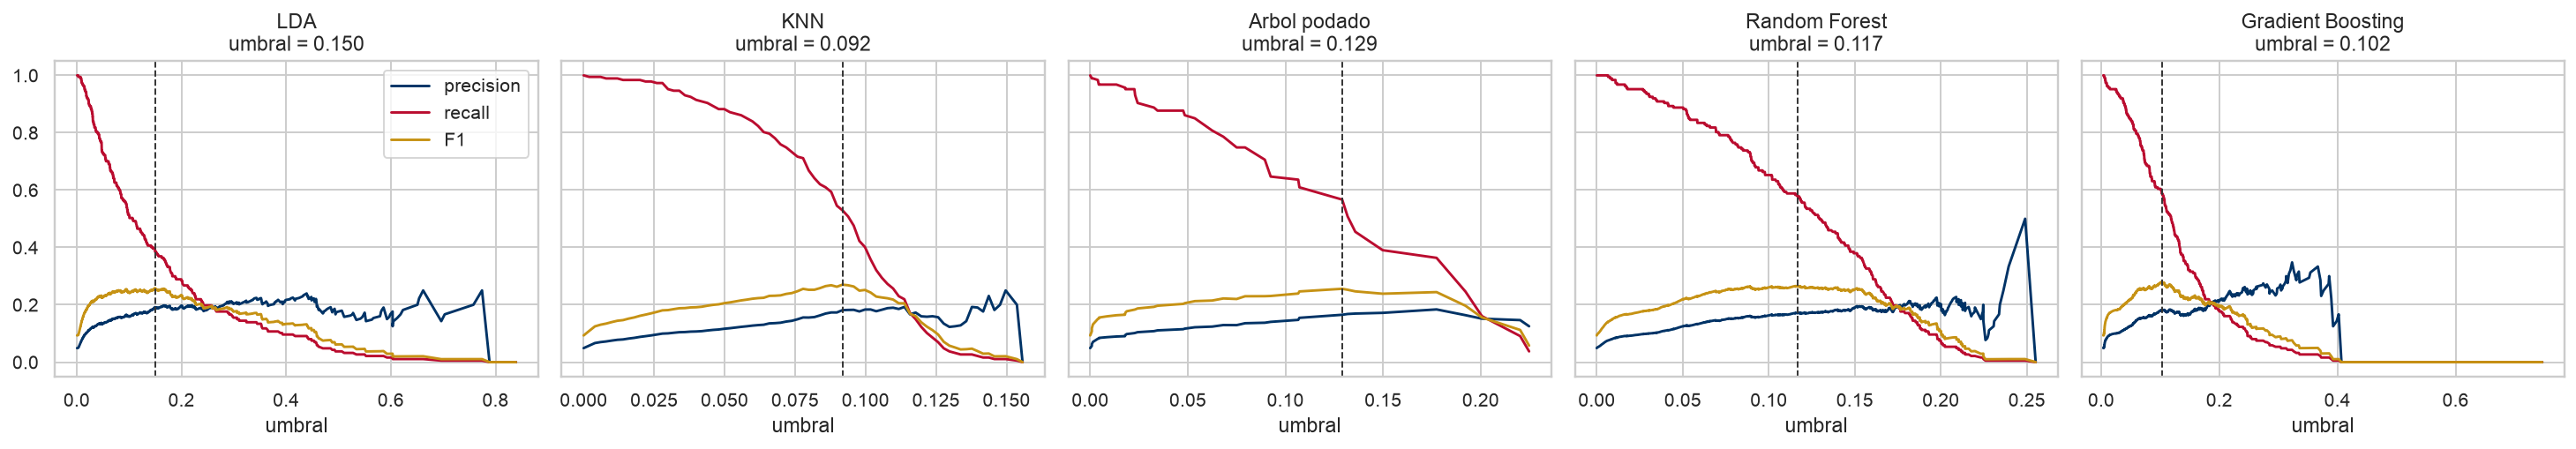

In [24]:
# umbral elegido en TRAIN: el que maximiza F1 sobre las probabilidades fuera de fold
umbrales = {}
fig, axes = plt.subplots(1, len(modelos), figsize=(4.2 * len(modelos), 3.8), sharey=True)
for ax, nombre in zip(axes, modelos):
    prec, rec, cortes = precision_recall_curve(y_train, proba_oof[nombre])
    f1 = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-12)
    mejor = np.argmax(f1)
    umbrales[nombre] = cortes[mejor]
    ax.plot(cortes, prec[:-1], color=UP_BLUE, label="precision")
    ax.plot(cortes, rec[:-1], color=UP_RED, label="recall")
    ax.plot(cortes, f1, color=UP_GOLD, label="F1")
    ax.axvline(cortes[mejor], color="#333333", ls="--", lw=1)
    ax.set_title(f"{nombre}\numbral = {cortes[mejor]:.3f}")
    ax.set_xlabel("umbral")
axes[0].legend()
plt.tight_layout()
plt.show()

In [25]:
# metricas en test con el umbral elegido por CV
tabla_final = tabla_metricas(umbrales)
tabla_final["AUC CV (train)"] = pd.Series(auc_cv)
display(tabla_final.round(3))

,umbral,TP,FN,FP,TN,accuracy,precision,recall,especificidad,F1,F1 macro,AUC,AP,AUC CV (train)
LDA,0.150,32,30,106,1110,0.894,0.232,0.516,0.913,0.320,0.631,0.836,0.254,0.832
KNN,0.092,44,18,184,1032,0.842,0.193,0.710,0.849,0.303,0.607,0.829,0.228,0.838
Arbol podado,0.129,26,36,99,1117,0.894,0.208,0.419,0.919,0.278,0.611,0.815,0.171,0.830
Random Forest,0.117,42,20,171,1045,0.851,0.197,0.677,0.859,0.305,0.611,0.836,0.257,0.844
Gradient Boosting,0.102,43,19,173,1043,0.850,0.199,0.694,0.858,0.309,0.613,0.840,0.246,0.842


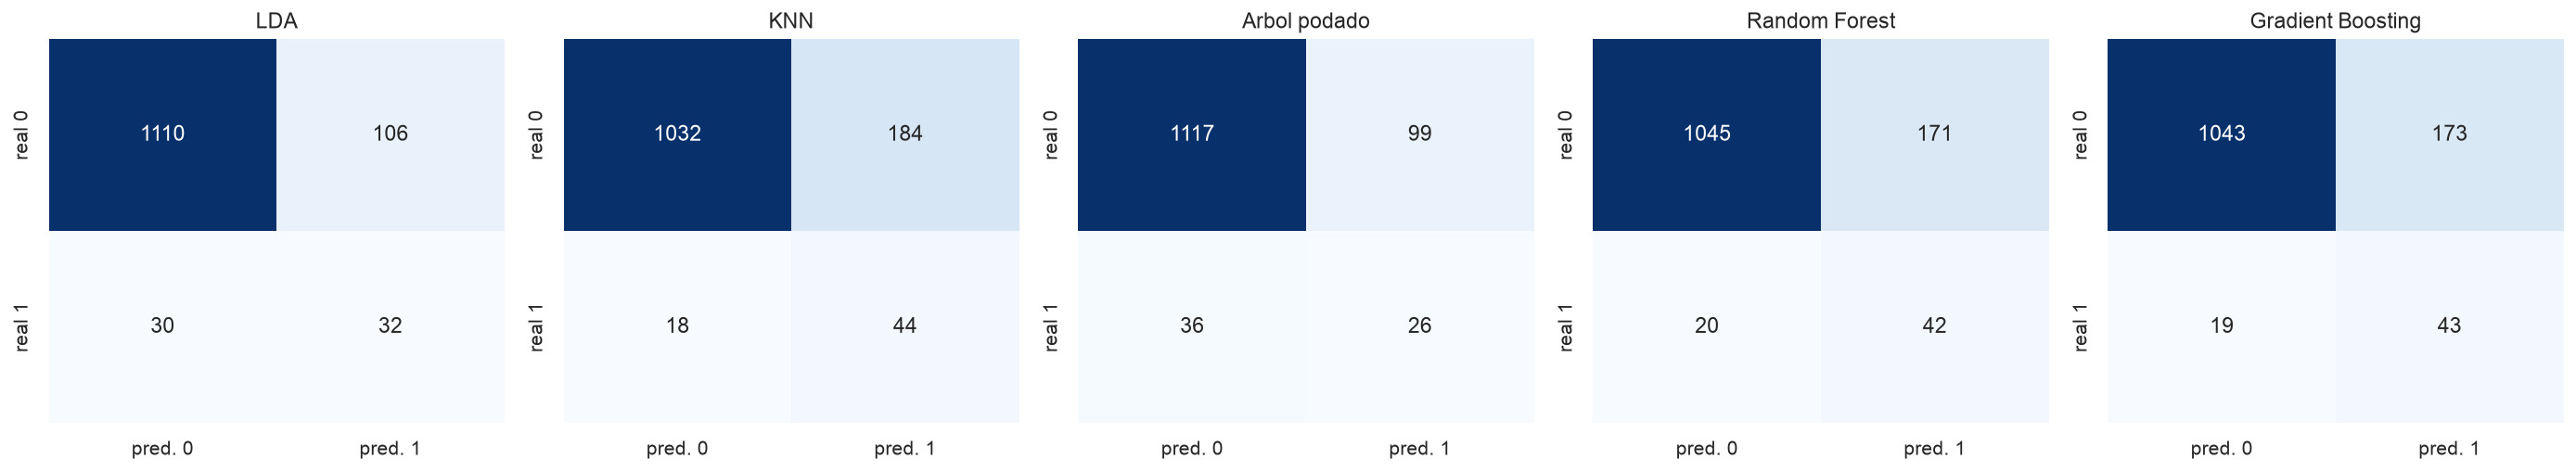

In [26]:
# matrices de confusion en test (filas = verdad, columnas = prediccion)
fig, axes = plt.subplots(1, len(modelos), figsize=(4 * len(modelos), 3.8))
for ax, nombre in zip(axes, modelos):
    pred = (proba_test[nombre] >= umbrales[nombre]).astype(int)
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["pred. 0", "pred. 1"], yticklabels=["real 0", "real 1"])
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

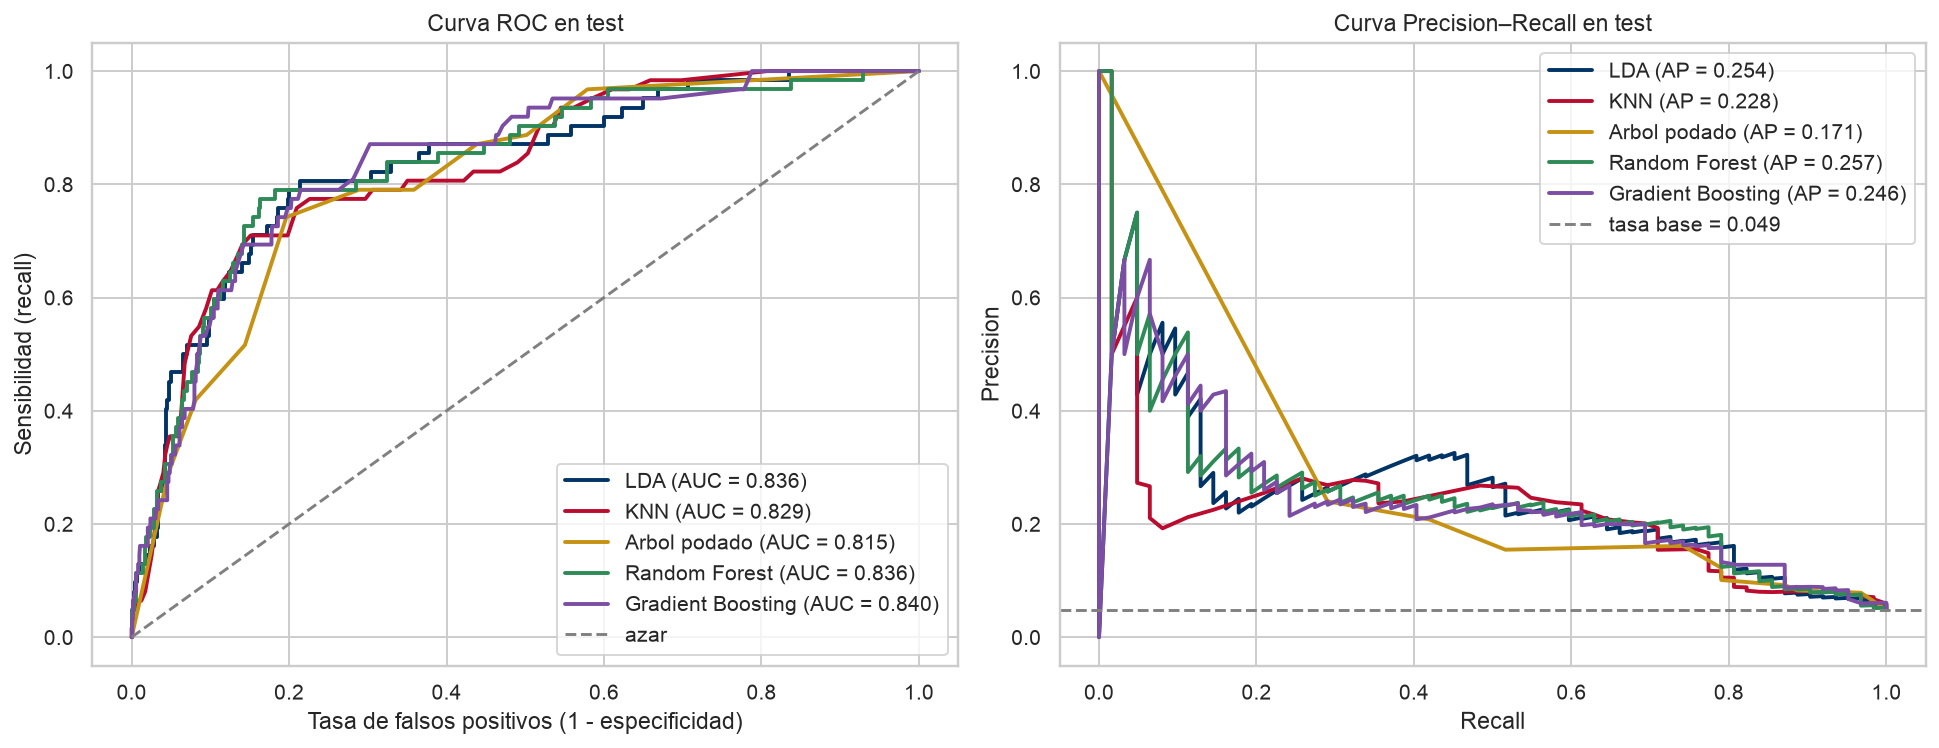

In [27]:
colores = [UP_BLUE, UP_RED, UP_GOLD, "#2E8B57", "#7B4EA3"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for (nombre, _), color in zip(modelos.items(), colores):
    fpr, tpr, _ = roc_curve(y_test, proba_test[nombre])
    axes[0].plot(fpr, tpr, color=color, lw=2,
                 label=f"{nombre} (AUC = {roc_auc_score(y_test, proba_test[nombre]):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, proba_test[nombre])
    axes[1].plot(rec, prec, color=color, lw=2,
                 label=f"{nombre} (AP = {average_precision_score(y_test, proba_test[nombre]):.3f})")
axes[0].plot([0, 1], [0, 1], color="gray", ls="--", label="azar")
axes[0].set_xlabel("Tasa de falsos positivos (1 - especificidad)")
axes[0].set_ylabel("Sensibilidad (recall)")
axes[0].set_title("Curva ROC en test")
axes[0].legend()
axes[1].axhline(y_test.mean(), color="gray", ls="--", label=f"tasa base = {y_test.mean():.3f}")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Curva Precision–Recall en test")
axes[1].legend()
plt.tight_layout()
plt.show()


---

## Parte 8 — ¿Cuál modelo generalizó mejor?

Comparamos AUC en train, CV y test. Una brecha grande train–test puede sugerir varianza alta; no es una prueba aislada de sobreajuste. El bootstrap usa los mismos índices de test para todos los modelos y permite describir incertidumbre y diferencias pareadas.

Los intervalos siguientes remuestrean el test con los modelos ya fijados. No incluyen la variación de entrenar de nuevo, la búsqueda de hiperparámetros ni cambios de población. Las fracciones de victorias bootstrap son descriptivas; no son p-valores ni probabilidades de superioridad clínica.


In [28]:
# generalizacion: AUC en train vs. CV vs. test
filas = []
for nombre, (modelo, cols) in modelos.items():
    auc_train = roc_auc_score(y_train, modelo.predict_proba(X_train[cols])[:, 1])
    auc_test = roc_auc_score(y_test, proba_test[nombre])
    filas.append({"modelo": nombre, "AUC train": auc_train, "AUC CV": auc_cv[nombre],
                  "AUC test": auc_test, "brecha train - test": auc_train - auc_test})
tabla_gen = pd.DataFrame(filas).set_index("modelo")
display(tabla_gen.round(3))

,AUC train,AUC CV,AUC test,brecha train - test
modelo,,,,
LDA,0.845,0.832,0.836,0.009
KNN,0.845,0.838,0.829,0.015
Arbol podado,0.855,0.830,0.815,0.040
Random Forest,0.895,0.844,0.836,0.060
Gradient Boosting,0.885,0.842,0.840,0.044


In [29]:
rng = np.random.default_rng(SEED)
B = 1000
y_test_arr = y_test.to_numpy()
n_test = len(y_test_arr)
boot = {nombre: [] for nombre in modelos}
for _ in range(B):
    idx = rng.integers(0, n_test, n_test)
    if np.unique(y_test_arr[idx]).size < 2:
        continue
    for nombre in modelos:
        boot[nombre].append(roc_auc_score(y_test_arr[idx], proba_test[nombre][idx]))

tabla_boot = pd.DataFrame({
    "AUC test": {nombre: roc_auc_score(y_test, proba_test[nombre]) for nombre in modelos},
    "error estandar (bootstrap)": {nombre: np.std(boot[nombre], ddof=1) for nombre in modelos},
    "IC95 inferior": {nombre: np.quantile(boot[nombre], 0.025) for nombre in modelos},
    "IC95 superior": {nombre: np.quantile(boot[nombre], 0.975) for nombre in modelos},
})
display(tabla_boot.round(3))
print("Remuestras válidas:", len(next(iter(boot.values()))), "de", B)

# El mayor AUC test se identifica solo para describir la comparación realizada.
mejor_modelo = tabla_boot["AUC test"].idxmax()
filas_diferencias = []
for nombre in modelos:
    if nombre == mejor_modelo:
        continue
    diferencias = np.asarray(boot[mejor_modelo]) - np.asarray(boot[nombre])
    filas_diferencias.append({
        "comparacion": f"{mejor_modelo} - {nombre}",
        "diferencia AUC test": tabla_boot.loc[mejor_modelo, "AUC test"] - tabla_boot.loc[nombre, "AUC test"],
        "IC95 inferior": np.quantile(diferencias, 0.025),
        "IC95 superior": np.quantile(diferencias, 0.975),
        "fraccion victorias bootstrap": np.mean(diferencias > 0),
    })
tabla_diferencias = pd.DataFrame(filas_diferencias).set_index("comparacion")
display(tabla_diferencias.round(3))
print("Ganador observado por AUC test:", mejor_modelo)
print("Candidato elegido antes de test por AUC CV:", modelo_seleccionado_cv)
print("No reajustamos los modelos ni sus umbrales después de observar estas tablas.")


,AUC test,error estandar (bootstrap),IC95 inferior,IC95 superior
LDA,0.836,0.027,0.782,0.882
KNN,0.829,0.025,0.779,0.878
Arbol podado,0.815,0.025,0.765,0.861
Random Forest,0.836,0.026,0.782,0.884
Gradient Boosting,0.840,0.024,0.791,0.883


Remuestras válidas: 1000 de 1000


,diferencia AUC test,IC95 inferior,IC95 superior,fraccion victorias bootstrap
comparacion,,,,
Gradient Boosting - LDA,0.005,-0.015,0.024,0.697
Gradient Boosting - KNN,0.011,-0.015,0.038,0.802
Gradient Boosting - Arbol podado,0.025,0.001,0.050,0.981
Gradient Boosting - Random Forest,0.005,-0.008,0.017,0.767


Ganador observado por AUC test: Gradient Boosting
Candidato elegido antes de test por AUC CV: Random Forest
No reajustamos los modelos ni sus umbrales después de observar estas tablas.


---

## Parte 9 — Conclusiones y siguientes pasos

La conclusión siguiente se genera con las métricas calculadas en esta ejecución, para evitar cifras desactualizadas.


In [30]:
mejor_f1 = tabla_final["F1"].idxmax()
mejor_recall = tabla_final["recall"].idxmax()
ganador = tabla_final["AUC"].idxmax()
ranking_test = tabla_final["AUC"].sort_values(ascending=False)
segundo = ranking_test.index[1]
diferencia_dos = np.asarray(boot[ganador]) - np.asarray(boot[segundo])
ic_diferencia = np.quantile(diferencia_dos, [0.025, 0.975])
incertidumbre = ("incluye cero, por lo que no afirmamos una ventaja concluyente"
                 if ic_diferencia[0] <= 0 <= ic_diferencia[1]
                 else "no incluye cero en este remuestreo; aun así, la comparación es descriptiva y depende de este test")
rf_hoja = rf.best_params_["modelo__min_samples_leaf"]
rf_m = rf.best_params_["modelo__max_features"]
conclusiones = f"""
**Dataset y EDA.** Elegimos un archivo público con {len(df):,} registros y diez predictores, porque combina variables continuas, binarias y categóricas, faltantes y desbalance. La clase positiva representa {df['stroke'].mean():.2%}. BMI falta en {df['bmi'].isna().sum()} registros; además, el valor Unknown de tabaquismo representa {(df['smoking_status'] == 'Unknown').mean():.1%}. No confundimos Unknown con una afirmación de que la persona nunca fumó. Un clasificador que siempre predice cero obtendría {1 - y_test.mean():.2%} de accuracy en test y recall cero, lo que explica usar AUC, precision, recall y F1.

**Qué aprendimos de los métodos.** LDA produce una frontera lineal con una covarianza compartida; QDA permite covarianzas por clase y fronteras curvas. Las dummies no son normales y algunas categorías tienen pocos positivos, así que sus supuestos son aproximaciones. Conservamos LDA por la estabilidad e interpretación de la frontera lineal, reconociendo lo que muestra la comparación CV. KNN depende de distancias y por eso imputamos y estandarizamos dentro de cada fold; la selección quedó en K = {knn.best_params_['modelo__n_neighbors']} con {len(cols_knn)} predictores. El árbol podado tiene {arbol_estimador.get_n_leaves()} hojas y profundidad {arbol_estimador.get_depth()}; limitar hojas y penalizar complejidad reduce la variabilidad de un árbol grande. Random Forest combina muestras bootstrap y subconjuntos de variables para reducir correlación entre árboles; su búsqueda eligió m = {rf_m} y mínimo {rf_hoja} observaciones por hoja. Boosting suma árboles en secuencia para corregir el error restante, controlando profundidad, número de árboles y learning rate.

**Resultados y generalización.** Antes de consultar test, el mayor AUC CV de los representantes finales fue el de **{modelo_seleccionado_cv}** ({auc_cv[modelo_seleccionado_cv]:.4f}). El mayor AUC observado en test fue **{ganador}** ({tabla_final.loc[ganador, 'AUC']:.4f}), con AP {tabla_final.loc[ganador, 'AP']:.4f}. Nuestra hipótesis es que las relaciones con edad y glucosa, junto con las diferencias entre subgrupos, permiten que los métodos flexibles capturen parte de la señal sin depender de una única distribución normal. Es una interpretación de los resultados, no una prueba causal. El IC bootstrap pareado del AUC de {ganador} menos {segundo} es [{ic_diferencia[0]:.4f}, {ic_diferencia[1]:.4f}] y {incertidumbre}. El test contiene solo {int(y_test.sum())} positivos; el ganador observado no implica superioridad segura.

**El umbral cambia la comparación.** Con umbrales elegidos solo en train, el mayor F1 de test corresponde a **{mejor_f1}** ({tabla_final.loc[mejor_f1, 'F1']:.4f}) y el mayor recall a **{mejor_recall}** ({tabla_final.loc[mejor_recall, 'recall']:.4f}). Por tanto, no existe un ganador único para todos los objetivos. La precisión de {ganador} es {tabla_final.loc[ganador, 'precision']:.4f}, con {int(tabla_final.loc[ganador, 'FP'])} falsos positivos y {int(tabla_final.loc[ganador, 'FN'])} falsos negativos: una AUC aceptable no elimina el problema de las falsas alarmas.

**Qué haríamos con más tiempo.** Añadiríamos un indicador de BMI faltante y lo evaluaríamos dentro de train; estudiaríamos regularización de QDA, otros rangos de K, calibración de probabilidades y selección de umbral con un coste explícito. Usaríamos CV anidada o una partición adicional para separar la elección de hiperparámetros y umbrales. Haríamos una validación externa y revisaríamos resultados por subgrupos antes de extrapolar conclusiones. Las importancias de Gini y los coeficientes muestran asociaciones del modelo, no causas.

**Fuente del dataset:** [Stroke Prediction Dataset, fedesoriano, Kaggle](https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset).
"""
display(Markdown(conclusiones))

# Comprobaciones finales del artefacto ejecutado.
assert set(modelos) == set(umbrales) == set(proba_test)
assert (tabla_final[["TP", "FN", "FP", "TN"]].sum(axis=1) == len(y_test)).all()
assert (tabla_final["TP"] + tabla_final["FN"] == y_test.sum()).all()
assert tabla_final[["AUC", "F1", "precision", "recall", "AP"]].apply(lambda col: col.between(0, 1)).all().all()
print("Verificación final: split disjunto, cinco Pipelines y métricas coherentes.")


**Dataset y EDA.** Elegimos un archivo público con 5,110 registros y diez predictores, porque combina variables continuas, binarias y categóricas, faltantes y desbalance. La clase positiva representa 4.87%. BMI falta en 201 registros; además, el valor Unknown de tabaquismo representa 30.2%. No confundimos Unknown con una afirmación de que la persona nunca fumó. Un clasificador que siempre predice cero obtendría 95.15% de accuracy en test y recall cero, lo que explica usar AUC, precision, recall y F1.

**Qué aprendimos de los métodos.** LDA produce una frontera lineal con una covarianza compartida; QDA permite covarianzas por clase y fronteras curvas. Las dummies no son normales y algunas categorías tienen pocos positivos, así que sus supuestos son aproximaciones. Conservamos LDA por la estabilidad e interpretación de la frontera lineal, reconociendo lo que muestra la comparación CV. KNN depende de distancias y por eso imputamos y estandarizamos dentro de cada fold; la selección quedó en K = 501 con 5 predictores. El árbol podado tiene 10 hojas y profundidad 5; limitar hojas y penalizar complejidad reduce la variabilidad de un árbol grande. Random Forest combina muestras bootstrap y subconjuntos de variables para reducir correlación entre árboles; su búsqueda eligió m = 6 y mínimo 50 observaciones por hoja. Boosting suma árboles en secuencia para corregir el error restante, controlando profundidad, número de árboles y learning rate.

**Resultados y generalización.** Antes de consultar test, el mayor AUC CV de los representantes finales fue el de **Random Forest** (0.8443). El mayor AUC observado en test fue **Gradient Boosting** (0.8405), con AP 0.2458. Nuestra hipótesis es que las relaciones con edad y glucosa, junto con las diferencias entre subgrupos, permiten que los métodos flexibles capturen parte de la señal sin depender de una única distribución normal. Es una interpretación de los resultados, no una prueba causal. El IC bootstrap pareado del AUC de Gradient Boosting menos Random Forest es [-0.0077, 0.0174] y incluye cero, por lo que no afirmamos una ventaja concluyente. El test contiene solo 62 positivos; el ganador observado no implica superioridad segura.

**El umbral cambia la comparación.** Con umbrales elegidos solo en train, el mayor F1 de test corresponde a **LDA** (0.3200) y el mayor recall a **KNN** (0.7097). Por tanto, no existe un ganador único para todos los objetivos. La precisión de Gradient Boosting es 0.1991, con 173 falsos positivos y 19 falsos negativos: una AUC aceptable no elimina el problema de las falsas alarmas.

**Qué haríamos con más tiempo.** Añadiríamos un indicador de BMI faltante y lo evaluaríamos dentro de train; estudiaríamos regularización de QDA, otros rangos de K, calibración de probabilidades y selección de umbral con un coste explícito. Usaríamos CV anidada o una partición adicional para separar la elección de hiperparámetros y umbrales. Haríamos una validación externa y revisaríamos resultados por subgrupos antes de extrapolar conclusiones. Las importancias de Gini y los coeficientes muestran asociaciones del modelo, no causas.

**Fuente del dataset:** [Stroke Prediction Dataset, fedesoriano, Kaggle](https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset).


Verificación final: split disjunto, cinco Pipelines y métricas coherentes.
